<a href="https://colab.research.google.com/github/Shreya090606/4NI25CS184_DAV_LAB/blob/main/Mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [25]:
df = pd.read_csv('/content/netflix_titles.csv')

In [26]:
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

print("\nColumn Information:")
print(df.info())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
print(df.describe(include='all'))

Dataset Shape: (8807, 12)

First 5 Records:
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA

In [27]:
# Indexing
print(df.loc[0:4, ['title', 'type', 'release_year']])

# Filtering
movies = df[df['type'] == 'Movie']
print(movies.head())

# Grouping
print(df.groupby('type').size())

# Aggregation
print(df.groupby('type')['release_year'].agg(
    ['mean', 'min', 'max']
))

                   title     type  release_year
0   Dick Johnson Is Dead    Movie          2020
1          Blood & Water  TV Show          2021
2              Ganglands  TV Show          2021
3  Jailbirds New Orleans  TV Show          2021
4           Kota Factory  TV Show          2021
   show_id   type                             title  \
0       s1  Movie              Dick Johnson Is Dead   
6       s7  Movie  My Little Pony: A New Generation   
7       s8  Movie                           Sankofa   
9      s10  Movie                      The Starling   
12     s13  Movie                      Je Suis Karl   

                         director  \
0                 Kirsten Johnson   
6   Robert Cullen, José Luis Ucha   
7                    Haile Gerima   
9                  Theodore Melfi   
12            Christian Schwochow   

                                                 cast  \
0                                                 NaN   
6   Vanessa Hudgens, Kimiko Glenn, James Mar

In [28]:
duration = pd.to_numeric(
    df[df['type'] == 'Movie']['duration'].astype(str)
    .str.extract(r'(\d+)')[0],
    errors='coerce'
).dropna()

print("Mean:", np.mean(duration))
print("Median:", np.median(duration))
print("Mode:", duration.mode().iloc[0])
print("Variance:", np.var(duration))
print("Standard Deviation:", np.std(duration))
print("25th Percentile:", np.percentile(duration, 25))
print("75th Percentile:", np.percentile(duration, 75))

Mean: 99.57718668407311
Median: 98.0
Mode: 90.0
Variance: 800.2270709364254
Standard Deviation: 28.2882850476381
25th Percentile: 87.0
75th Percentile: 114.0


Skewness: 0.20252952201069446
Kurtosis: 2.2913605764820355


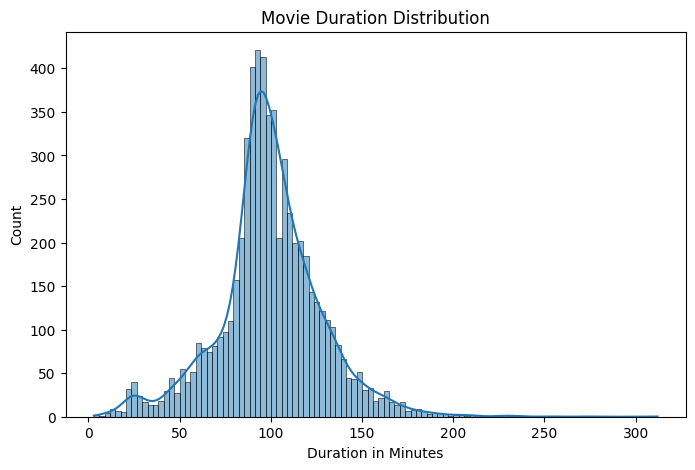

In [29]:
print("Skewness:", stats.skew(duration))
print("Kurtosis:", stats.kurtosis(duration))

plt.figure(figsize=(8, 5))
sns.histplot(duration, kde=True)

plt.title("Movie Duration Distribution")
plt.xlabel("Duration in Minutes")
plt.show()

Correlation:
              release_year  duration_num
release_year      1.000000     -0.249182
duration_num     -0.249182      1.000000

Covariance:
              release_year  duration_num
release_year     77.803809   -111.688062
duration_num   -111.688062   2582.146723


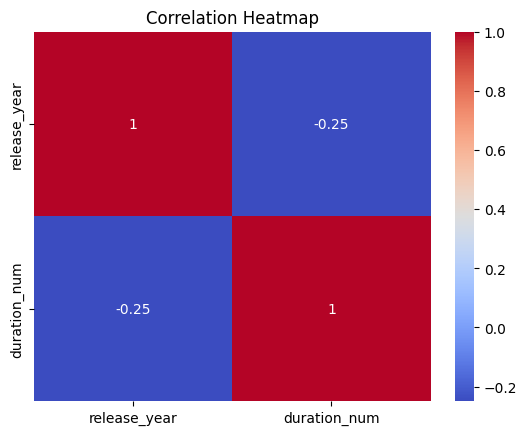

In [30]:
numeric_data = df[['release_year']].copy()

numeric_data['duration_num'] = pd.to_numeric(
    df['duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

numeric_data = numeric_data.dropna()

print("Correlation:")
print(numeric_data.corr())

print("\nCovariance:")
print(numeric_data.cov())

sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [31]:
# T-test: Movie duration comparison between two countries
country_data = df[df['type'] == 'Movie'].copy()

country_data['duration_num'] = pd.to_numeric(
    country_data['duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

country_data = country_data.dropna(subset=['duration_num'])

countries = (
    country_data['country'].dropna()
    .str.split(', ').explode()
    .value_counts().head(2).index
)

g1 = country_data[
    country_data['country'].str.contains(countries[0], na=False, regex=False)
]['duration_num']

g2 = country_data[
    country_data['country'].str.contains(countries[1], na=False, regex=False)
]['duration_num']

t_stat, p_value = stats.ttest_ind(g1, g2, equal_var=False)

print("T-test P-value:", p_value)

# Chi-square: Content type and rating
table = pd.crosstab(df['type'], df['rating'])

chi2, p, dof, expected = stats.chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p)

T-test P-value: 7.291972106815517e-188
Chi-square: 1047.6941440561634
P-value: 6.822436324208583e-213


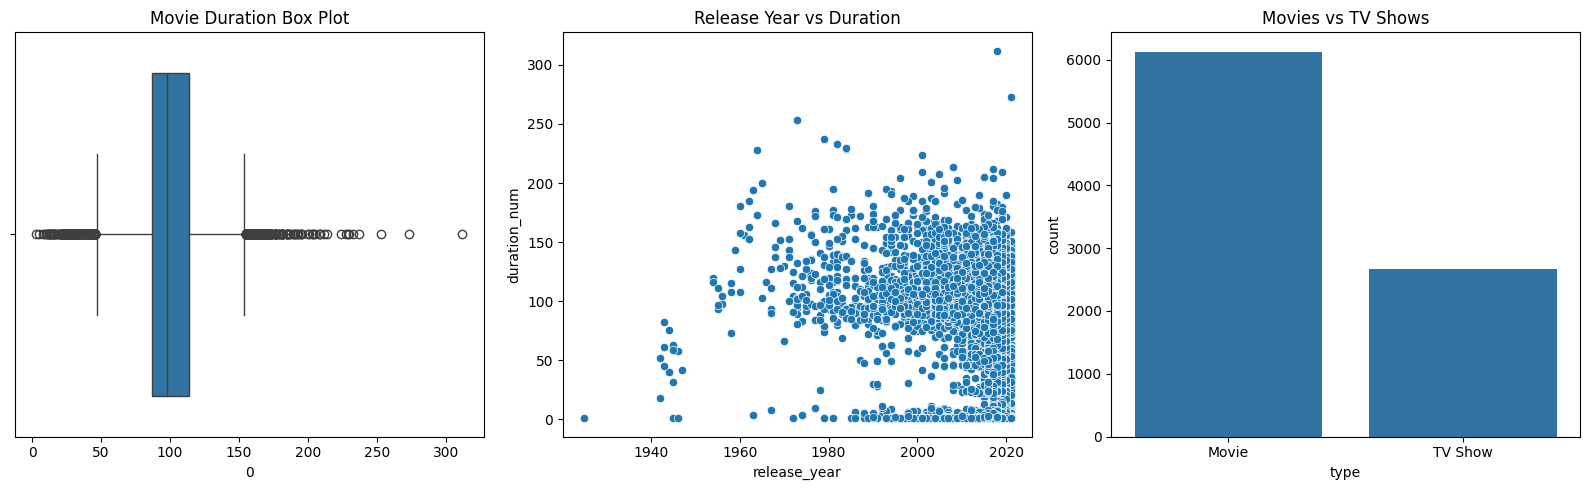

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x=duration, ax=axes[0])
axes[0].set_title("Movie Duration Box Plot")

sns.scatterplot(
    data=numeric_data,
    x='release_year',
    y='duration_num',
    ax=axes[1]
)
axes[1].set_title("Release Year vs Duration")

sns.countplot(data=df, x='type', ax=axes[2])
axes[2].set_title("Movies vs TV Shows")

plt.tight_layout()
plt.show()

In [33]:
clean_df = df.copy()

print("Missing Values:")
print(clean_df.isnull().sum())

print("Duplicate Rows:", clean_df.duplicated().sum())

clean_df = clean_df.drop_duplicates()

text_columns = [
    'director', 'cast', 'country',
    'rating', 'date_added', 'duration',
    'listed_in', 'description'
]

for col in text_columns:
    clean_df[col] = clean_df[col].fillna('Unknown')

clean_df['release_year'] = clean_df['release_year'].fillna(
    clean_df['release_year'].median()
)

print("\nMissing Values After Cleaning:")
print(clean_df.isnull().sum())

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64
Duplicate Rows: 0

Missing Values After Cleaning:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [34]:
Q1 = duration.quantile(0.25)
Q3 = duration.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers_iqr = duration[
    (duration < lower) | (duration > upper)
]

z_scores = stats.zscore(duration)

outliers_z = duration[np.abs(z_scores) > 3]

print("IQR Outliers:", len(outliers_iqr))
print("Z-score Outliers:", len(outliers_z))

IQR Outliers: 450
Z-score Outliers: 56


In [35]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

values = duration.values.reshape(-1, 1)

# Normalization
normalizer = MinMaxScaler()
normalized = normalizer.fit_transform(values)

# Standardization
standardizer = StandardScaler()
standardized = standardizer.fit_transform(values)

print("Normalized Values:\n", normalized[:5])
print("Standardized Values:\n", standardized[:5])

# Categorical encoding
encoded = pd.get_dummies(
    clean_df[['type', 'rating']].head(10),
    dtype=int
)

print(encoded)

Normalized Values:
 [[0.2815534 ]
 [0.28478964]
 [0.39482201]
 [0.32686084]
 [0.4012945 ]]
Standardized Values:
 [[-0.33855664]
 [-0.30320632]
 [ 0.89870465]
 [ 0.15634788]
 [ 0.9694053 ]]
   type_Movie  type_TV Show  rating_PG  rating_PG-13  rating_TV-14  \
0           1             0          0             1             0   
1           0             1          0             0             0   
2           0             1          0             0             0   
3           0             1          0             0             0   
4           0             1          0             0             0   
5           0             1          0             0             0   
6           1             0          1             0             0   
7           1             0          0             0             0   
8           0             1          0             0             1   
9           1             0          0             1             0   

   rating_TV-MA  
0             0  
1   

In [36]:
# Splitting and exploding genres
genre_data = clean_df[['title', 'listed_in']].copy()
genre_data['listed_in'] = genre_data['listed_in'].str.split(', ')
genre_data = genre_data.explode('listed_in')

print(genre_data.head())

# Merging
titles = clean_df[['show_id', 'title', 'type']].copy()
ratings = clean_df[['show_id', 'rating']].copy()

merged = pd.merge(titles, ratings, on='show_id')
print(merged.head())

# Joining
joined = titles.set_index('show_id').join(
    ratings.set_index('show_id'),
    lsuffix='_left',
    rsuffix='_right'
)

print(joined.head())

# Pivot table
pivot = pd.pivot_table(
    clean_df,
    index='release_year',
    columns='type',
    values='show_id',
    aggfunc='count'
)

print(pivot.tail())

                  title               listed_in
0  Dick Johnson Is Dead           Documentaries
1         Blood & Water  International TV Shows
1         Blood & Water               TV Dramas
1         Blood & Water            TV Mysteries
2             Ganglands          Crime TV Shows
  show_id                  title     type rating
0      s1   Dick Johnson Is Dead    Movie  PG-13
1      s2          Blood & Water  TV Show  TV-MA
2      s3              Ganglands  TV Show  TV-MA
3      s4  Jailbirds New Orleans  TV Show  TV-MA
4      s5           Kota Factory  TV Show  TV-MA
                         title     type rating
show_id                                       
s1        Dick Johnson Is Dead    Movie  PG-13
s2               Blood & Water  TV Show  TV-MA
s3                   Ganglands  TV Show  TV-MA
s4       Jailbirds New Orleans  TV Show  TV-MA
s5                Kota Factory  TV Show  TV-MA
type          Movie  TV Show
release_year                
2017          767.0    265.0
20

In [37]:
from sklearn.decomposition import PCA

features = clean_df[
    ['release_year', 'rating', 'country', 'listed_in']
].copy()

print("Selected Features:")
print(features.head())

# PCA using numerical features
pca_data = clean_df[['release_year']].copy()

pca_data['duration_num'] = pd.to_numeric(
    clean_df['duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

pca_data = pca_data.dropna()

scaler = StandardScaler()
scaled_data = scaler.fit_transform(pca_data)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

print("Explained Variance:")
print(pca.explained_variance_ratio_)

Selected Features:
   release_year rating        country  \
0          2020  PG-13  United States   
1          2021  TV-MA   South Africa   
2          2021  TV-MA        Unknown   
3          2021  TV-MA        Unknown   
4          2021  TV-MA          India   

                                           listed_in  
0                                      Documentaries  
1    International TV Shows, TV Dramas, TV Mysteries  
2  Crime TV Shows, International TV Shows, TV Act...  
3                             Docuseries, Reality TV  
4  International TV Shows, Romantic TV Shows, TV ...  
Explained Variance:
[0.62459077 0.37540923]


In [38]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Filter out classes in the target variable with fewer than 2 members to support stratified splitting
type_counts = clean_df['type'].value_counts()
valid_types = type_counts[type_counts >= 2].index
filtered_df = clean_df[clean_df['type'].isin(valid_types)].copy()

X = filtered_df[
    ['release_year', 'rating', 'country', 'listed_in']
].copy()

y = filtered_df['type']

X = pd.get_dummies(X, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Accuracy:", model.score(X_test, y_test))

Model Accuracy: 0.7434733257661748


Accuracy: 0.7434733257661748
Precision: 0.8028739168260179
Recall: 0.7434733257661748
F1 Score: 0.6715239444365828

Classification Report:
              precision    recall  f1-score   support

       Movie       0.73      1.00      0.84      1227
     TV Show       0.97      0.16      0.28       535

    accuracy                           0.74      1762
   macro avg       0.85      0.58      0.56      1762
weighted avg       0.80      0.74      0.67      1762



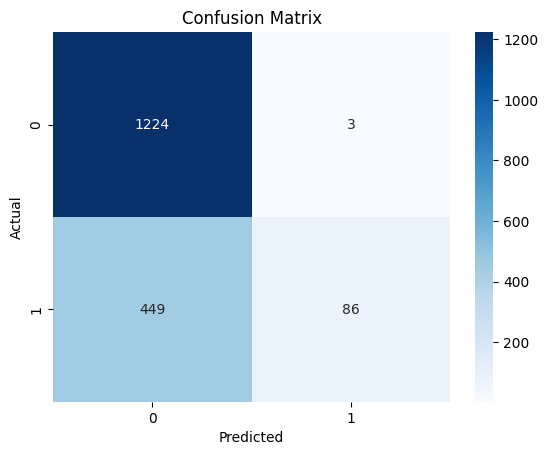

Cross-validation scores: [0.67593644 0.62599319 0.74616695 0.76660988 0.75298126]
Average: 0.7135375434837676


In [39]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, X, y, cv=5)

print("Cross-validation scores:", scores)
print("Average:", scores.mean())

In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

reg_data = clean_df[clean_df['type'] == 'Movie'].copy()

reg_data['duration_num'] = pd.to_numeric(
    reg_data['duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

reg_data = reg_data.dropna(
    subset=['release_year', 'duration_num']
)

X_reg = reg_data[['release_year']]
y_reg = reg_data['duration_num']

xr_train, xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_model = LinearRegression()
reg_model.fit(xr_train, yr_train)

yr_pred = reg_model.predict(xr_test)

print("MSE:", mean_squared_error(yr_test, yr_pred))
print("R2 Score:", r2_score(yr_test, yr_pred))

MSE: 703.6649724914507
R2 Score: 0.006001119648834541


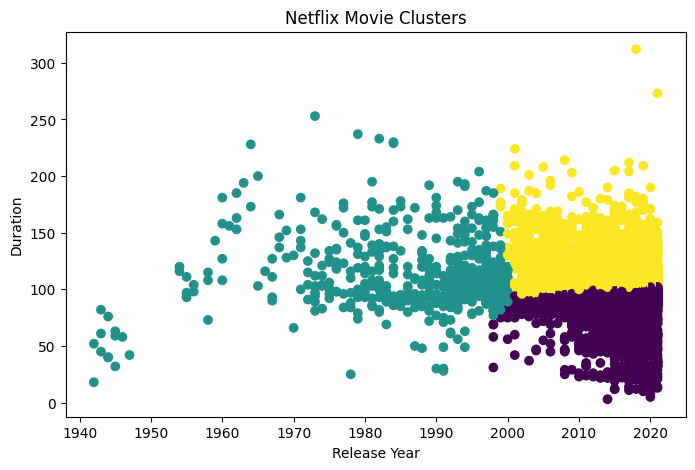

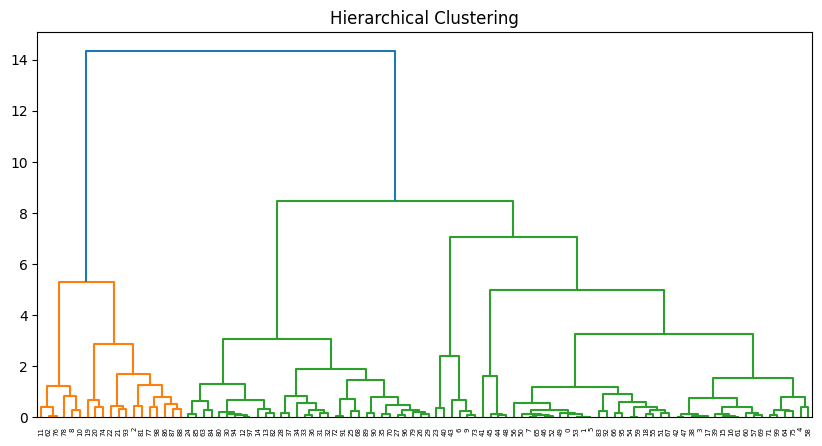

In [41]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

cluster_data = reg_data[['release_year', 'duration_num']].copy()

cluster_scaled = StandardScaler().fit_transform(cluster_data)

# K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(cluster_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    cluster_data['release_year'],
    cluster_data['duration_num'],
    c=clusters
)

plt.title("Netflix Movie Clusters")
plt.xlabel("Release Year")
plt.ylabel("Duration")
plt.show()

# Hierarchical clustering using a small sample
linked = linkage(cluster_scaled[:100], method='ward')

plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title("Hierarchical Clustering")
plt.show()

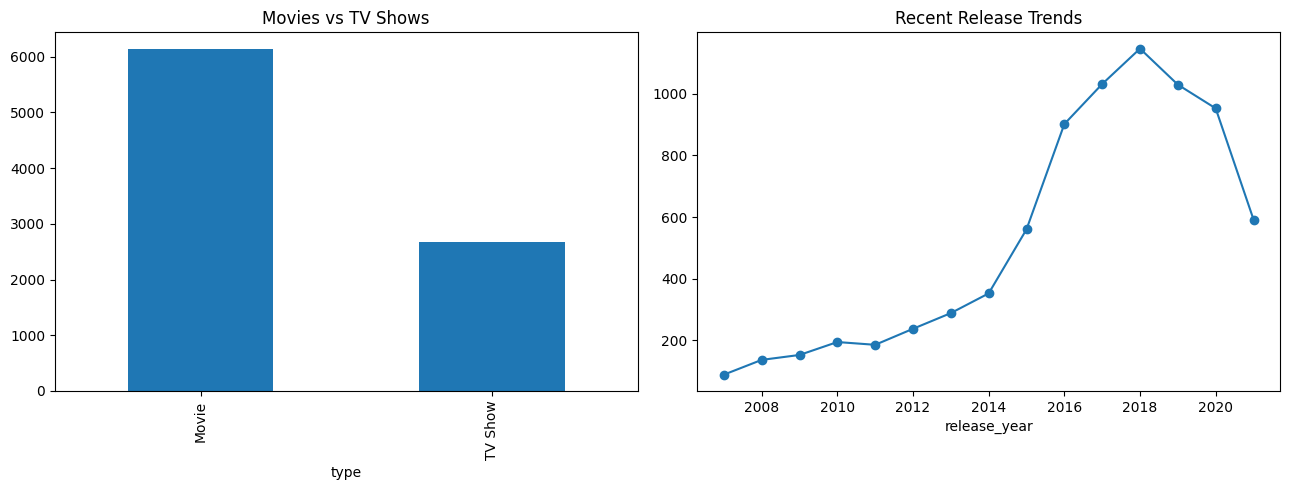

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = clean_df['type'].value_counts()

counts.plot(kind='bar', ax=axes[0])
axes[0].set_title("Movies vs TV Shows")

years = clean_df['release_year'].value_counts().sort_index().tail(15)

years.plot(kind='line', marker='o', ax=axes[1])
axes[1].set_title("Recent Release Trends")

plt.tight_layout()
plt.show()

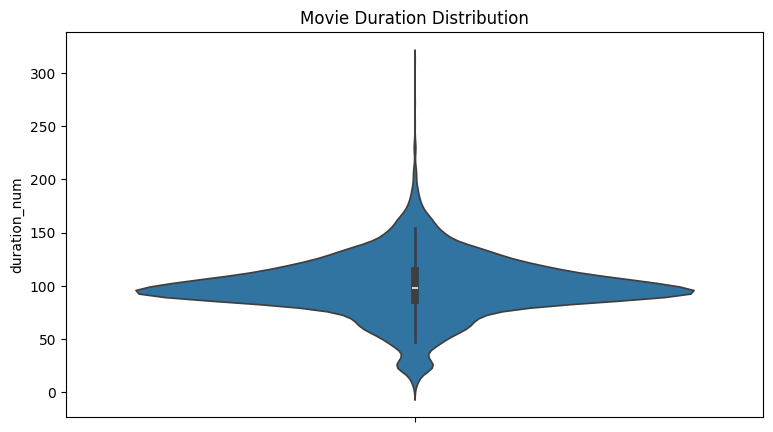

In [43]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=reg_data,
    y='duration_num'
)

plt.title("Movie Duration Distribution")
plt.show()

In [44]:
import plotly.express as px

genre_counts = (
    clean_df['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
    .reset_index()
)

genre_counts.columns = ['Genre', 'Count']

fig = px.bar(
    genre_counts,
    x='Genre',
    y='Count',
    title='Top 10 Netflix Genres'
)

fig.show()